# Avaliação matemática de sítios no polo sul lunar

## Pergunta
A topografia elevada favorece, de forma consistente, a iluminação solar e a visibilidade geométrica da Terra nos pontos candidatos analisados?

## Resultado em uma frase
Os quatro pontos mostram **compromissos entre critérios**, não uma regra universal segundo a qual “mais alto é sempre melhor”. Shoemaker tem a maior iluminação amostrada; Malapert e Faustini têm a maior visibilidade média da Terra; Malapert tem a menor declividade local. Isso é evidência comparativa para esses pontos, mas **não prova causalidade nem segurança de pouso**.

Este notebook reavalia a hipótese com a amostragem NASA/LOLA do notebook validado. Ele também separa medidas observadas de modelos teóricos simplificados, para não apresentar uma simulação idealizada como observação.

## O que os arquivos de referência permitem concluir

O documento de apoio relata que áreas elevadas tenderiam a ter mais Sol e melhor visibilidade da Terra. O primeiro notebook tenta ilustrar essa ideia com equações periódicas e um score de pesos escolhidos manualmente. Essas contas **não demonstram a teoria**: a conversão de altitude em graus no horizonte não tem justificativa geométrica, a iluminação é imposta por uma senoide simplificada, e o score depende de pesos arbitrários. A coincidência entre esses resultados e a hipótese não é validação independente.

O segundo notebook é mais apropriado para comparação observacional: usa produtos LOLA/NASA, coordenadas catalogadas e amostras locais. Ainda assim, são somente quatro pontos centrais, não regiões de pouso completas. As médias de iluminação e visibilidade são climatológicas de longo prazo; visibilidade geométrica não equivale a enlace de rádio. Portanto, a afirmação forte do documento de apoio deve ser tratada como hipótese exploratória.

**Teste operacional neste notebook:** comparar, ponto a ponto, quatro métricas ( iluminação, visibilidade da Terra, elevação e declividade ), procurar dominância entre critérios e calcular correlações apenas como descrição dos quatro registros. Com n = 4 não se fará inferência populacional nem teste de significância.

## Dados, unidades e amostragem

- Iluminação e visibilidade da Terra: mapas LOLA polares, resolução nominal de 60 m/pixel. Em cada ponto, mediana de janela 5×5 (cerca de 300 m de lado).
- Elevação e declividade: produtos LOLA locais de 5 m/pixel. Em cada ponto, mediana de janela 11×11 (cerca de 55 m de lado).
- Coordenadas: pontos catalogados na Tabela A2-2 do *Lunar Surface Data Book* da NASA; coordenadas transformadas para estereográfica polar sul numa esfera de raio 1.737.400 m.
- Os valores de iluminação e Terra são percentuais médios de longo prazo, não uma previsão de uma missão em datas específicas.

Fontes indicadas no notebook validado: [NASA PGDA — LOLA Polar Illumination](https://pgda.gsfc.nasa.gov/products/69), [NASA PGDA — High-Resolution LOLA Topography](https://pgda.gsfc.nasa.gov/products/78), [NASA — Lunar Surface Data Book](https://ntrs.nasa.gov/citations/20230007818).

**Para executar:** mantenha a pasta nasaHack_dados ao lado do notebook, ou ajuste DATA_DIR na próxima célula. Dependências: numpy, pandas, matplotlib, rasterio e pyproj. Os dez GeoTIFFs são grandes; este notebook não baixa arquivos automaticamente.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyproj import CRS, Transformer
import rasterio
from IPython.display import display

# Procura os arquivos junto ao notebook e na pasta Downloads usada na análise original.
candidates = [Path.cwd() / "nasaHack_dados", Path.home() / "Downloads" / "nasaHack_dados"]
DATA_DIR = next((p for p in candidates if p.is_dir()), candidates[0])
print(f"Pasta de dados: {DATA_DIR}")
if not DATA_DIR.is_dir():
    raise FileNotFoundError("Não encontrei nasaHack_dados. Ajuste DATA_DIR para a pasta que contém os GeoTIFFs.")

Pasta de dados: C:\Users\Mateu\nasaHack_dados


In [8]:
SITES = {
    "Shackleton Rim (R04)": {"lat": -89.7668, "lon": -171.87, "raster": "Site04"},
    "Malapert Massif (R23)": {"lat": -85.9948, "lon": -0.23578, "raster": "Site23"},
    "Shoemaker (centro)": {"lat": -87.1835, "lon": 62.83502, "raster": "Shoemaker"},
    "Faustini Rim A (LM7)": {"lat": -87.8897, "lon": 90.0, "raster": "LM7"},
}

# Projeção estereográfica polar sul na esfera lunar usada no estudo de referência.
R_LUA_M = 1_737_400.0
crs_geo = CRS.from_proj4(
    f"+proj=longlat +a={R_LUA_M} +b={R_LUA_M} +no_defs +type=crs")
crs_polar = CRS.from_proj4(
    f"+proj=stere +lat_0=-90 +lat_ts=-90 +lon_0=0 "
    f"+a={R_LUA_M} +b={R_LUA_M} +units=m +no_defs +type=crs")
transformer = Transformer.from_crs(crs_geo, crs_polar, always_xy=True)

files = {
    "solar": "AVGVISIB_85S_060M_201608.TIF",
    "earth": "AVGVISIB_85S_060M_201608_EARTH.TIF",
}

def median_window(filename, x, y, radius):
    """Lê janela centrada no ponto, respeitando máscara, escala e offset do GeoTIFF."""
    with rasterio.open(DATA_DIR / filename) as ds:
        row, col = ds.index(x, y)
        r0, r1 = max(0, row-radius), min(ds.height, row+radius+1)
        c0, c1 = max(0, col-radius), min(ds.width, col+radius+1)
        window = ((r0, r1), (c0, c1))
        a = ds.read(1, window=window, masked=True).astype("float64")
        a = a.filled(np.nan) * ds.scales[0] + ds.offsets[0]
        return float(np.nanmedian(a)), int(np.isfinite(a).sum())

rows = []
for name, site in SITES.items():
    x, y = transformer.transform(site["lon"], site["lat"])
    s, n_s = median_window(files["solar"], x, y, radius=2)
    e, n_e = median_window(files["earth"], x, y, radius=2)
    slope, n_topo = median_window(f'{site["raster"]}_slope.tif', x, y, radius=5)
    elev, _ = median_window(f'{site["raster"]}_dem.tif', x, y, radius=5)
    rows.append({
        "Local": name, "Latitude (°)": site["lat"], "Longitude (°)": site["lon"],
        "Iluminação (%)": 100*s, "Terra visível (%)": 100*e,
        "Declividade (°)": slope, "Elevação LOLA (m)": elev,
        "Pixels válidos 60 m (Sol/Terra)": f"{n_s}/{n_e}",
        "Pixels válidos 5 m": n_topo,
    })

results = pd.DataFrame(rows)
metrics = ["Iluminação (%)", "Terra visível (%)", "Declividade (°)", "Elevação LOLA (m)"]
display(results.round(2))

,Local,Latitude (°),Longitude (°),Iluminação (%),Terra visível (%),Declividade (°),Elevação LOLA (m),Pixels válidos 60 m (Sol/Terra),Pixels válidos 5 m
0,Shackleton Rim (R04),-89.77,-171.87,10.96,11.07,31.50,771.04,25/25,121
1,Malapert Massif (R23),-85.99,-0.24,28.16,50.00,3.71,4783.57,25/25,121
2,Shoemaker (centro),-87.18,62.84,34.38,43.46,5.19,547.57,25/25,121
3,Faustini Rim A (LM7),-87.89,90.00,24.02,50.80,4.16,46.21,25/25,121


## Formulação matemática

Para cada sítio (i), sejam (S_i) a mediana percentual de iluminação, (E_i) a mediana percentual de visibilidade geométrica da Terra, (	heta_i) a mediana da declividade em graus e (z_i) a mediana de elevação do produto LOLA em metros. As medidas são obtidas por:

[
S_i = 100,operatorname{mediana}(s_{ij}),qquad
E_i = 100,operatorname{mediana}(e_{ij}),qquad
	heta_i = operatorname{mediana}(	heta_{ij}),qquad
z_i = operatorname{mediana}(z_{ij}),
]

onde (j) percorre os pixels válidos da janela local e (s_{ij},e_{ij}) já incorporam a escala e o offset declarados nos GeoTIFFs.

A alegação “maior altitude implica melhores condições” exigiria que (z) variasse de modo consistente com (S) e (E), além de controlar posição, geometria do horizonte e características do terreno. Com quatro pontos catalogados, correlações são somente estatísticas descritivas: elas não identificam causa. Também evitamos somar critérios em um score único sem limites operacionais e pesos justificados.

In [7]:
# Reproduz os valores reportados no notebook validado, com pequena tolerância de arredondamento.
expected = pd.DataFrame({
    "Local": ["Shackleton Rim (R04)", "Malapert Massif (R23)", "Shoemaker (centro)", "Faustini Rim A (LM7)"],
    "Iluminação (%)": [10.96, 28.16, 34.38, 24.02],
    "Terra visível (%)": [11.07, 50.00, 43.46, 50.80],
    "Declividade (°)": [31.50, 3.71, 5.19, 4.16],
    "Elevação LOLA (m)": [771.04, 4783.57, 547.57, 46.21],
})
check = results.merge(expected, on="Local", suffixes=("_calculado", "_referência"))
for col in ["Iluminação (%)", "Terra visível (%)", "Declividade (°)", "Elevação LOLA (m)"]:
    delta = (check[f"{col}_calculado"] - check[f"{col}_referência"]).abs().max()
    print(f"Diferença máxima em {col}: {delta:.4f}")

leaders = {
    "Maior iluminação": results.loc[results["Iluminação (%)"].idxmax(), "Local"],
    "Maior visibilidade da Terra": results.loc[results["Terra visível (%)"].idxmax(), "Local"],
    "Menor declividade": results.loc[results["Declividade (°)"].idxmin(), "Local"],
    "Maior elevação": results.loc[results["Elevação LOLA (m)"].idxmax(), "Local"],
}
print("Melhor valor observado por critério:")
for k, v in leaders.items(): print(f"- {k}: {v}")


Diferença máxima em Iluminação (%): 0.0040
Diferença máxima em Terra visível (%): 0.0040
Diferença máxima em Declividade (°): 0.0031
Diferença máxima em Elevação LOLA (m): 0.0032
Melhor valor observado por critério:
- Maior iluminação: Shoemaker (centro)
- Maior visibilidade da Terra: Faustini Rim A (LM7)
- Menor declividade: Malapert Massif (R23)
- Maior elevação: Malapert Massif (R23)


## Correlação e dominância

A correlação de Pearson resume associação linear; Spearman resume associação monotônica por postos. Valores próximos de ±1 podem parecer fortes mesmo com quatro observações, então são exibidos como descrição do conjunto, sem p-valor e sem extrapolação.

Um ponto (A) domina (B) se for pelo menos tão bom em todos os critérios escolhidos (mais Sol, mais Terra visível, menor declividade, maior elevação) e estritamente melhor em pelo menos um. A fronteira de Pareto mostra os pontos que não são dominados nesse conjunto de critérios. Ela não escolhe uma missão vencedora: essa decisão depende de requisitos operacionais explícitos.

In [4]:
corr_inputs = ["Elevação LOLA (m)", "Iluminação (%)", "Terra visível (%)", "Declividade (°)"]
print("Correlação de Pearson (descritiva; n=4)")
display(results[corr_inputs].corr(method="pearson").round(3))
print("Correlação de Spearman (descritiva; n=4)")
display(results[corr_inputs].corr(method="spearman").round(3))

# Maximizar Sol, Terra e elevação; minimizar declividade.
def domina(a, b):
    nao_pior = (a["Iluminação (%)"] >= b["Iluminação (%)"] and
                a["Terra visível (%)"] >= b["Terra visível (%)"] and
                a["Elevação LOLA (m)"] >= b["Elevação LOLA (m)"] and
                a["Declividade (°)"] <= b["Declividade (°)"])
    melhor_em_um = (a["Iluminação (%)"] > b["Iluminação (%)"] or
                    a["Terra visível (%)"] > b["Terra visível (%)"] or
                    a["Elevação LOLA (m)"] > b["Elevação LOLA (m)"] or
                    a["Declividade (°)"] < b["Declividade (°)"])
    return nao_pior and melhor_em_um

pareto = []
for _, b in results.iterrows():
    dominated_by = [a["Local"] for _, a in results.iterrows() if a["Local"] != b["Local"] and domina(a, b)]
    pareto.append({"Local": b["Local"], "Dominado por": ", ".join(dominated_by) if dominated_by else "Não"})
display(pd.DataFrame(pareto))

Correlação de Pearson (descritiva; n=4)


,Elevação LOLA (m),Iluminação (%),Terra visível (%),Declividade (°)
Elevação LOLA (m),1.000,0.203,0.285,-0.263
Iluminação (%),0.203,1.000,0.817,-0.887
Terra visível (%),0.285,0.817,1.000,-0.991
Declividade (°),-0.263,-0.887,-0.991,1.000


Correlação de Spearman (descritiva; n=4)


,Elevação LOLA (m),Iluminação (%),Terra visível (%),Declividade (°)
Elevação LOLA (m),1.0,0.0,-0.4,-0.2
Iluminação (%),0.0,1.0,0.2,-0.4
Terra visível (%),-0.4,0.2,1.0,-0.8
Declividade (°),-0.2,-0.4,-0.8,1.0


,Local,Dominado por
0,Shackleton Rim (R04),Malapert Massif (R23)
1,Malapert Massif (R23),Não
2,Shoemaker (centro),Não
3,Faustini Rim A (LM7),Não


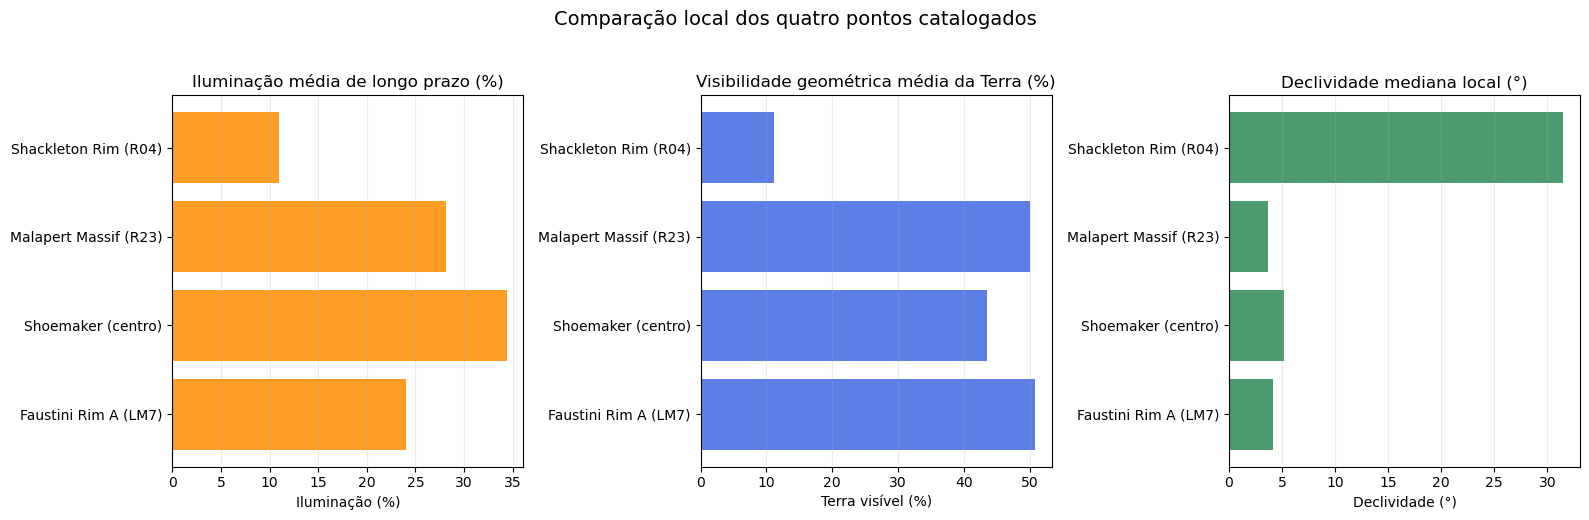

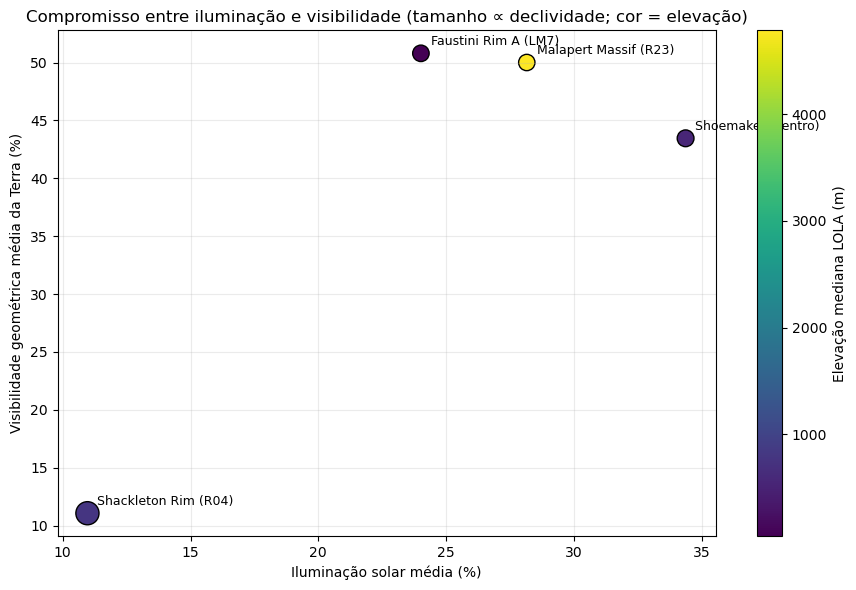

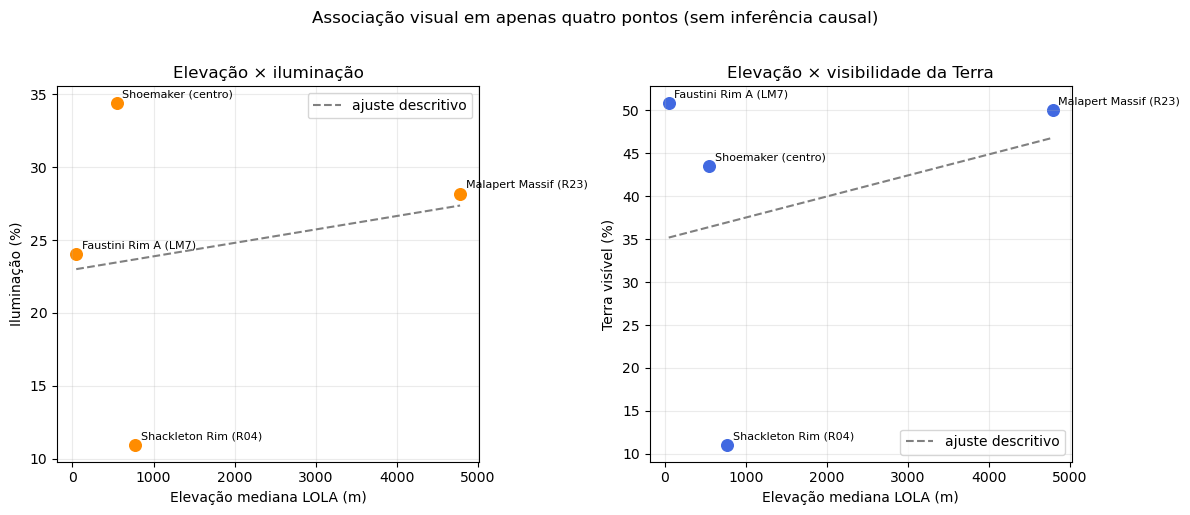

In [9]:
# Gráfico 1: três variáveis operacionais, cada uma em sua própria escala.
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
plots = [
    ("Iluminação (%)", "Iluminação média de longo prazo (%)", "darkorange"),
    ("Terra visível (%)", "Visibilidade geométrica média da Terra (%)", "royalblue"),
    ("Declividade (°)", "Declividade mediana local (°)", "seagreen"),
]
for ax, (col, title, color) in zip(axes, plots):
    ax.barh(results["Local"], results[col], color=color, alpha=.86)
    ax.set_title(title)
    ax.grid(axis="x", alpha=.25)
    ax.set_xlabel(col)
    ax.invert_yaxis()
fig.suptitle("Comparação local dos quatro pontos catalogados", y=1.03, fontsize=14)
fig.tight_layout()
plt.show()

# Gráfico 2: compromisso entre energia e visibilidade, colorido por elevação.
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(results["Iluminação (%)"], results["Terra visível (%)"],
                s=120 + 5*results["Declividade (°)"],
                c=results["Elevação LOLA (m)"], cmap="viridis", edgecolor="black")
for _, r in results.iterrows():
    ax.annotate(r["Local"], (r["Iluminação (%)"], r["Terra visível (%)"]),
                xytext=(7, 6), textcoords="offset points", fontsize=9)
ax.set_xlabel("Iluminação solar média (%)")
ax.set_ylabel("Visibilidade geométrica média da Terra (%)")
ax.set_title("Compromisso entre iluminação e visibilidade (tamanho ∝ declividade; cor = elevação)")
fig.colorbar(sc, ax=ax, label="Elevação mediana LOLA (m)")
ax.grid(alpha=.25)
fig.tight_layout()
plt.show()

# Gráfico 3: altitude versus cada medida; os pontos são os dados, linhas apenas guias lineares.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, ycol, title, color in [
    (axes[0], "Iluminação (%)", "Elevação × iluminação", "darkorange"),
    (axes[1], "Terra visível (%)", "Elevação × visibilidade da Terra", "royalblue"),
]:
    x = results["Elevação LOLA (m)"].to_numpy()
    y = results[ycol].to_numpy()
    ax.scatter(x, y, color=color, s=70)
    for _, r in results.iterrows(): ax.annotate(r["Local"], (r["Elevação LOLA (m)"], r[ycol]), xytext=(4,4), textcoords="offset points", fontsize=8)
    coef = np.polyfit(x, y, 1)
    grid = np.linspace(x.min(), x.max(), 100)
    ax.plot(grid, np.polyval(coef, grid), color="gray", linestyle="--", label="ajuste descritivo")
    ax.set_title(title); ax.set_xlabel("Elevação mediana LOLA (m)"); ax.set_ylabel(ycol); ax.grid(alpha=.25); ax.legend()
fig.suptitle("Associação visual em apenas quatro pontos (sem inferência causal)", y=1.02)
fig.tight_layout()
plt.show()

## Conclusão matemática e alcance da evidência

A amostragem reproduz quatro padrões distintos:

- **Shoemaker** maximiza a iluminação média amostrada (34,38%).
- **Faustini Rim A** maximiza a visibilidade média da Terra (50,80%); Malapert fica muito próximo (50,00%).
- **Malapert** tem a menor declividade mediana (3,71°), mas não a maior iluminação.
- **Shackleton Rim**, no ponto central catalogado, tem os menores valores de iluminação e visibilidade da Terra e a maior declividade local. Isso descreve uma vizinhança de cerca de 55 m para topografia, não toda a borda da cratera.

Logo, a frase “regiões elevadas tendem a oferecer melhores condições” **não fica comprovada como lei geral** por esses materiais. O notebook simples anterior não fornece demonstração matemática independente; o notebook LOLA fornece evidência observacional útil, mas a amostra é pequena, pontual e não controla outras variáveis. Os resultados sustentam que a posição e a topografia local importam e que os critérios podem entrar em conflito.

Para demonstrar causalidade ou recomendar um local, seria necessário analisar áreas de pouso (ROIs) em vez de quatro centros, considerar distribuições espaciais e incertezas, modelar horizonte/efemérides para datas de missão e especificar requisitos de energia, enlace de rádio, pouso e navegação. A porcentagem de Terra geometricamente visível não mede qualidade de comunicação.

In [6]:
# Comparação ordinal com os quatro critérios tratados como igualmente importantes.
# Ranks baixos são melhores; a pontuação total menor indica melhor equilíbrio neste conjunto.
ranked = results[["Local"]].copy()
ranked["Rank iluminação"] = results["Iluminação (%)"].rank(ascending=False, method="min").astype(int)
ranked["Rank Terra"] = results["Terra visível (%)"].rank(ascending=False, method="min").astype(int)
ranked["Rank declividade"] = results["Declividade (°)"].rank(ascending=True, method="min").astype(int)
ranked["Rank elevação"] = results["Elevação LOLA (m)"].rank(ascending=False, method="min").astype(int)
rank_cols = ["Rank iluminação", "Rank Terra", "Rank declividade", "Rank elevação"]
ranked["Soma dos ranks"] = ranked[rank_cols].sum(axis=1)
ranked = ranked.sort_values(["Soma dos ranks", "Local"]).reset_index(drop=True)
display(ranked)
print("Menor soma = melhor equilíbrio ordinal sob pesos iguais para os quatro critérios.")

,Local,Rank iluminação,Rank Terra,Rank declividade,Rank elevação,Soma dos ranks
0,Malapert Massif (R23),2,2,1,1,6
1,Faustini Rim A (LM7),3,1,2,4,10
2,Shoemaker (centro),1,3,3,3,10
3,Shackleton Rim (R04),4,4,4,2,14


Menor soma = melhor equilíbrio ordinal sob pesos iguais para os quatro critérios.


## Conclusão final integrada: recomendação do DOCX e dados LOLA

O DOCX do projeto indica como áreas promissoras as **regiões elevadas próximas às bordas de Shackleton e Malapert A/IM-1**, além de áreas próximas a **Shoemaker**. Também aponta interiores de crateras e zonas baixas com baixos percentuais de Sol/Terra como menos favoráveis. Abaixo, essa recomendação é confrontada com os valores dos pontos medidos neste notebook.

| Local ou zona | O que os dados deste notebook mostram | Conclusão para a seleção |
|---|---|---|
| **Malapert Massif (R23)** | 28,16% de iluminação, 50,00% de Terra visível, menor declividade (3,71°) e maior elevação entre os quatro pontos. Lidera a classificação ordinal equilibrada. | **Melhor compromisso medido entre os quatro pontos; prioridade para estudos adicionais.** O arquivo identifica R23 como Malapert Massif; sua equivalência exata a Malapert A/IM-1 não é estabelecida pelos dados aqui analisados. |
| **Shoemaker (centro)** | Maior iluminação (34,38%); 43,46% de Terra visível e declividade de 5,19°. | **Candidato forte quando energia solar é prioridade**, em linha com a inclusão de Shoemaker no DOCX. O ponto central não representa todas as áreas elevadas da borda nem o interior inteiro. |
| **Região elevada próxima a Shackleton** | O ponto catalogado R04 analisado teve 10,96% de iluminação, 11,07% de Terra visível e declividade de 31,50%. | O DOCX mantém a região como candidata, mas **o ponto efetivamente amostrado não confirma essa vantagem**. A conclusão só pode ser aplicada à vizinhança amostrada; é necessário medir outras áreas elevadas da borda antes de recomendar a região. |
| **Faustini Rim A (LM7)** | Maior visibilidade da Terra (50,80%), 24,02% de iluminação e 4,16° de declividade. | Bom resultado para visibilidade geométrica da Terra. Este é um ponto de borda catalogado; não deve ser confundido com o interior de Faustini citado entre as áreas menos favoráveis no DOCX. |
| **Interiores de crateras e áreas baixas** | Não foram amostrados separadamente como regiões completas neste notebook. | Mantêm-se como **áreas a evitar segundo a hipótese e os mapas descritos no DOCX**, mas esta tabela de quatro pontos não quantifica nem comprova todos esses interiores. |

### Decisão

**Entre os quatro pontos medidos, Malapert Massif (R23) é o melhor compromisso geral; Shoemaker é a escolha mais forte para maximizar iluminação; Faustini Rim A para maximizar visibilidade geométrica da Terra; e o ponto Shackleton Rim (R04) é o menos favorável na amostra.** Para a shortlist regional do projeto, manter Malapert A/IM-1, as bordas elevadas de Shackleton e áreas candidatas de Shoemaker, mas tratar Shackleton como hipótese a verificar com amostragem de uma área maior.

Assim, a recomendação do DOCX é considerada sem atribuir ao ponto R04 resultados que ele não apresenta. A classificação é conclusiva apenas para os quatro pontos e os critérios analisados; não aprova um local para pouso real. Visibilidade geométrica da Terra não garante enlace de rádio, e médias de longo prazo não substituem simulação para datas e duração específicas da missão.

## Referências e rastreabilidade

As fontes e os parâmetros de processamento abaixo foram transcritos do notebook validado fornecido:

1. NASA PGDA, [LOLA Polar Illumination](https://pgda.gsfc.nasa.gov/products/69) — iluminação e visibilidade média da Terra.
2. NASA PGDA, [High-Resolution LOLA Topography for Lunar South Pole Sites](https://pgda.gsfc.nasa.gov/products/78) — modelos de elevação e declividade.
3. NASA, [Lunar Surface Data Book (2023)](https://ntrs.nasa.gov/citations/20230007818) — nomes e coordenadas dos pontos catalogados.
4. NASA Moon Trek, [ferramenta cartográfica lunar](https://trek.nasa.gov/moon/).

A reprodução numérica confirma que o pipeline executado produz valores compatíveis com a tabela validada; isso verifica a consistência da amostragem, não a exatidão absoluta dos produtos, as hipóteses físicas ou a adequação de um sítio a uma missão.